# Complete preprocessing walkthrough: extracted tracks to model-ready sequences

This notebook consolidates your preprocessing history, including the pilot, quality corrections, outlier investigation, temporary four-note experiment, one-bar rebuild and final four-bar variable-length dataset. It uses actual repository files and existing preprocessing functions, shows intermediate calculations, and verifies real saved values.

**Run All is an inspection, not a production rebuild.** It reads existing extraction/intermediate/final files and reconstructs selected steps in memory. It neither reruns audio extraction nor writes datasets, vocabularies, checkpoints or other notebooks. Historical rebuild commands are documented at the end, not executed.

The dataset unit is **one beat per token**; the final grouping unit is **up to four consecutive source bars per sequence**. Full melody is preserved on retained beats. Quality-family basic chords are inputs; detailed reference chords are targets. These references are automatic pseudo-labels.

## Contents
1. Environment and evidence inventory
2. Extraction inputs and their validation
3. Single-track pilot and beat intervals
4. Melody overlap and detailed reference alignment
5. Canonicalization and synthetic basic-quality rules
6. Musical/progression context and audit separation
7. All-track discovery and historical quality corrections
8. Outlier, exclusions and the temporary four-note limit
9. Group splits, training-only vocabularies and unknowns
10. All numerical features, melody timing and mask semantics
11. One-bar to four-bar grouping, boundaries and irregular metadata
12. Ragged NPZ storage, dynamic batch padding and decoding
13. Readable CSV round-trip checks and dataset-wide coverage
14. Actual model input subset, reproducibility and limitations

Each result is labelled as a live calculation, an in-memory reconstruction, or a recorded historical build report. The supplied explanation's statement that no model was trained is outdated: baseline, weighted and multi-task experiments now exist; training is downstream of the preprocessing explained here.

In [1]:
from pathlib import Path
import sys,json,csv,hashlib,copy,inspect,math,html
from collections import Counter
import numpy as np
import torch
import matplotlib.pyplot as plt
from IPython.display import display,HTML,Markdown

cwd=Path.cwd().resolve()
candidates=[cwd,*cwd.parents,cwd/'vocal-harmonization']
ROOT=next((p for p in candidates if (p/'experiments/rahul/src/encode_features.py').exists()),None)
if ROOT is None: raise FileNotFoundError('Open this notebook inside the vocal-harmonization repository.')
if str(ROOT) not in sys.path: sys.path.insert(0,str(ROOT))
BASE=ROOT/'experiments/rahul'
FINAL=BASE/'outputs/model_preprocessing/final_all_tracks_quality_v6_multibar'
csv.field_size_limit(64*1024*1024)
from experiments.rahul.src.build_synthetic_dataset import read_csv,melody_features,align,simplify,context,join_roman
from experiments.rahul.src.canonicalize_chords import canonicalize_chord
from experiments.rahul.src.encode_features import FeatureEncoder,load_events,CATEGORICAL,USED_INPUTS,FORBIDDEN_INPUTS,supported_target
from experiments.rahul.src.build_final_dataset import discover
from experiments.rahul.src.rebuild_four_note_dataset import remove_outlier_window
from experiments.rahul.src.rebuild_bar_dataset import BarTracks
from experiments.rahul.src.create_sequences import validate_splits,sequence_windows
from experiments.rahul.src.transformer_dataset import SavedSequenceDataset,ChordSequenceDataset,collate_sequences
from experiments.rahul.src.export_readable_sequences import readable_rows

def read_json(path): return json.loads(Path(path).read_text(encoding='utf-8'))
def table(rows):
    rows=list(rows)
    if not rows: display(Markdown('*No rows.*'));return
    keys=list(dict.fromkeys(k for row in rows for k in row))
    def text(v):
        if isinstance(v,(dict,list,tuple)): v=json.dumps(v,ensure_ascii=False)
        return html.escape(str(v))
    display(HTML('<div style="overflow-x:auto"><table><thead><tr>'+''.join('<th>'+text(k)+'</th>' for k in keys)+'</tr></thead><tbody>'+''.join('<tr>'+''.join('<td>'+text(row.get(k,''))+'</td>' for k in keys)+'</tr>' for row in rows)+'</tbody></table></div>'))
def sha(path):
    h=hashlib.sha256()
    with Path(path).open('rb') as f:
        for block in iter(lambda:f.read(8*1024*1024),b''):h.update(block)
    return h.hexdigest()
settings=read_json(FINAL/'preprocessing_config.json')
stats=read_json(FINAL/'preprocessing_statistics.json')
validation=read_json(FINAL/'preprocessing_validation_report.json')
ready=read_json(FINAL/'FINAL_DATASET_READY.json')
split_manifest=read_json(FINAL/'split_manifest.json')
encoder=FeatureEncoder.load(FINAL)
SOURCE=ROOT/settings['source_root'];PHASE1=ROOT/settings['phase1_output_root']
protected=[p for p in (BASE/'notebooks').glob('*.ipynb') if p.name!='10_complete_preprocessing_walkthrough.ipynb']
protected+=list((BASE/'src').rglob('*.py'))
protected_before={str(p):sha(p) for p in protected}
print('Repository:',ROOT,'\nFinal snapshot:',FINAL)
print('Python:',sys.version.split()[0],'Torch:',torch.__version__)
table([{'split':s,**{k:v[k] for k in ('tracks','bars','sequences','real_beats','valid_targets','invalid_targets','silent_beats')}} for s,v in stats.items()])

Matplotlib is building the font cache; this may take a moment.


Could not save font_manager cache [Errno 13] Permission denied: 'C:\\Users\\srjay\\.matplotlib\\fontlist-v3.11.0.json.matplotlib-lock'


Repository: C:\Users\srjay\OneDrive\Desktop\Research\vocal-harmonization 
Final snapshot: C:\Users\srjay\OneDrive\Desktop\Research\vocal-harmonization\experiments\rahul\outputs\model_preprocessing\final_all_tracks_quality_v6_multibar
Python: 3.12.10 Torch: 2.14.1+cpu


split,tracks,bars,sequences,real_beats,valid_targets,invalid_targets,silent_beats
train,470,50159,12718,186572,184867,1705,25052
validation,23,3201,814,11319,11214,105,1170
test,32,3905,990,14278,14077,201,1810


## 1. Extraction inputs and validation

The upstream extraction pipeline supplies combined melody notes, detected beats/bars, detailed LV-Chordia chord intervals, source Roman interpretations and melody-derived key estimates. `build_synthetic_dataset.py` consumes these outputs; it does not rerun the audio models. The separate `build_training_events.py` pYIN path is an alternative experiment, not the source of this final synthetic dataset.

Required extraction files: `melody/combined.csv`, `chords/full.csv`, `roman/full.csv`, `beats/beats.csv`, `beats/beats.json`, `chords/full.json`. `key.json` and genre annotations are optional in the builder: missing categories stay unknown, not fabricated. The annotation TSV also supplies artist/album identities for group splitting.

The builder validates matching track IDs, finite/ordered times, positive intervals, MIDI bounds, consistent durations, non-overlapping reference segments and exact chord/Roman correspondence. Batch chord endpoints allow an explicit 1-second tolerance matching the upstream extractor; the pilot default is 0.01 seconds. Source timestamps are preserved, not clipped. Source hashes provide provenance.

In [2]:
TRACK='382';NAME=f'track_{int(TRACK):07d}';pilot_source=SOURCE/NAME
raw_notes=read_csv(pilot_source/'melody/combined.csv')
raw_chords=read_csv(pilot_source/'chords/full.csv')
raw_romans=read_csv(pilot_source/'roman/full.csv')
raw_beats=read_csv(pilot_source/'beats/beats.csv')
beat_doc=read_json(pilot_source/'beats/beats.json');chord_doc=read_json(pilot_source/'chords/full.json')
notes=copy.deepcopy(raw_notes);chords=copy.deepcopy(raw_chords)
for row in notes:
    for k in ('onset_sec','offset_sec','midi_pitch'):row[k]=float(row[k])
    row['midi_pitch_rounded']=int(float(row['midi_pitch_rounded']))
for row in chords:
    for k in ('start_sec','end_sec'):row[k]=float(row[k])
joined=join_roman(chords,raw_romans)
duration=float(beat_doc['duration_sec'])
assert duration==float(chord_doc['duration_sec'])
assert all(0<=r['midi_pitch']<=127 and r['onset_sec']<r['offset_sec'] for r in notes)
assert all(a['onset_sec']<=b['onset_sec'] for a,b in zip(notes,notes[1:]))
assert all(a['end_sec']<=b['start_sec']+1e-8 for a,b in zip(chords,chords[1:]))
table([{'source':p,'exists':(pilot_source/p).exists()} for p in ('melody/combined.csv','chords/full.csv','roman/full.csv','beats/beats.csv','beats/beats.json','chords/full.json','key.json')])
print('Raw melody notes:');table(raw_notes[:3])
print('Raw detailed chord segments:');table(raw_chords[:3])
print('Raw beat/bar rows:');table(raw_beats[:4])
print('Genre annotations:',(ROOT/'datasets/mtg-jamendo/annotations/autotagging_genre.tsv').exists())
print('Validated chord/Roman joins:',len(joined),'Batch endpoint tolerance:',settings['chord_endpoint_tolerance_sec'])

source,exists
melody/combined.csv,True
chords/full.csv,True
roman/full.csv,True
beats/beats.csv,True
beats/beats.json,True
chords/full.json,True
key.json,True


Raw melody notes:


track_id,onset_sec,offset_sec,midi_pitch,midi_pitch_rounded,velocity,source,model_midi_pitch
382,0.0099,0.24479,69,69,100,sheetsage2_instrumental,
382,0.24479,1.3099,69,69,100,sheetsage2_instrumental,
382,1.3099,1.90521,69,69,100,sheetsage2_instrumental,


Raw detailed chord segments:


track_id,start_sec,end_sec,chord_label,root,quality,bass_degree
382,0.0,0.56,N,,,
382,0.56,4.37,F:maj/3,F,maj,3
382,4.37,9.08,Bb:maj,Bb,maj,


Raw beat/bar rows:


track_id,beat_index,time_sec,beat_in_bar,bar_index,meter_numerator,meter_denominator,is_downbeat
382,0,0.01,1,0,4,4,True
382,1,0.48,2,0,4,4,False
382,2,1.01,3,0,4,4,False
382,3,1.61,4,0,4,4,False


Genre annotations: True
Validated chord/Roman joins: 77 Batch endpoint tolerance: 1.0


## 2. Pilot and beat-level events

Track 382 developed the initial alignment and encoding. The original fixed-window pilot used eight beats per sequence and included trailing padding. Here the event and padding counts are calculated from actual events and window construction.

A beat starts at its detected timestamp and ends at the next beat; the final detected beat ends at validated audio duration. No extra beat is invented before the first detection. `bar_number` retains zero-based source bar indices, and `beat_position` is one-based. These are source metadata, not guaranteed musicological ground truth.

In [3]:
pilot_path=PHASE1/NAME/f'{NAME}_training_events.csv'
rows,schema=load_events(pilot_path)
by_beat={r['beat_index']:r for r in rows}
intervals=[{'beat_index':int(b['beat_index']),'start_sec':float(b['time_sec']),
    'end_sec':float(raw_beats[i+1]['time_sec']) if i+1<len(raw_beats) else duration,
    'bar_number':int(b['bar_index']),'beat_position':int(b['beat_in_bar'])} for i,b in enumerate(raw_beats)]
for event,interval in zip(rows,intervals):
    assert event['beat_index']==interval['beat_index']
    assert event['start_sec']==interval['start_sec'] and event['end_sec']==interval['end_sec']
windows=sequence_windows({TRACK:rows},sequence_length=8)
print('Reconstructed historical eight-beat pilot:',{'real_beats':len(rows),'sequences':len(windows),'stored_positions':8*len(windows),'padding_positions':8*len(windows)-len(rows)})
table(intervals[:5]+intervals[-2:])
print('Intermediate Phase 1 schema roles:');table([{'role':role,'columns':schema.get(role+'_columns',[])} for role in ('input','target','metadata')])

Reconstructed historical eight-beat pilot: {'real_beats': 428, 'sequences': 54, 'stored_positions': 432, 'padding_positions': 4}


beat_index,start_sec,end_sec,bar_number,beat_position
0,0.01,0.48,0,1
1,0.48,1.01,0,2
2,1.01,1.61,0,3
3,1.61,2.2,0,4
4,2.2,2.76,1,1
426,209.96,210.52,106,3
427,210.52,211.04,106,4


Intermediate Phase 1 schema roles:


role,columns
input,"[""basic_chord"", ""basic_root"", ""basic_quality"", ""basic_root_pitch_class"", ""basic_chord_canonical"", ""melody_midi"", ""melody_pitch_classes"", ""melody_durations"", ""melody_relative_start"", ""melody_overlap_durations"", ""melody_sources"", ""genre_tags"", ""key"", ""mode"", ""key_confidence"", ""roman_numeral"", ""harmonic_function"", ""beat_index"", ""bar_number"", ""beat_position"", ""previous_basic_chord"", ""next_basic_chord"", ""event_duration""]"
target,"[""reference_chord"", ""reference_chord_canonical"", ""reference_root_pitch_class"", ""reference_quality"", ""reference_bass_degree"", ""reference_overlap_ratio"", ""target_valid""]"
metadata,[]


## 3. Every overlapping melody note is attached to a beat

Positive interval overlap is `max(0, min(note_end, beat_end) - max(note_start, beat_start))`. A sustained note can occur in multiple beat events. Multiple entries mean notes intersecting a beat interval, not necessarily simultaneous polyphony.

Each note retains fractional MIDI pitch, pitch class, original duration, onset relative to the beat, overlapping duration and extraction source. Negative relative onset and durations longer than one beat are valid. Source order is preserved; no quantization, transposition, augmentation or fitted pitch scaling is applied.

Real demonstration beat:

 4 interval: 2.2 2.76


note_index,midi,source,original_duration_sec,relative_onset_sec,overlap_sec
0,65.0,sheetsage2_instrumental,0.575,-0.2947900000000001,0.28020999999999985
1,65.0,sheetsage2_instrumental,0.13958000000000004,0.28020999999999985,0.13958000000000004
2,65.0,sheetsage2_instrumental,0.14010999999999996,0.4197899999999999,0.14010999999999996
3,65.0,sheetsage2_instrumental,0.10989000000000004,0.5598999999999998,9.999999999976694e-05


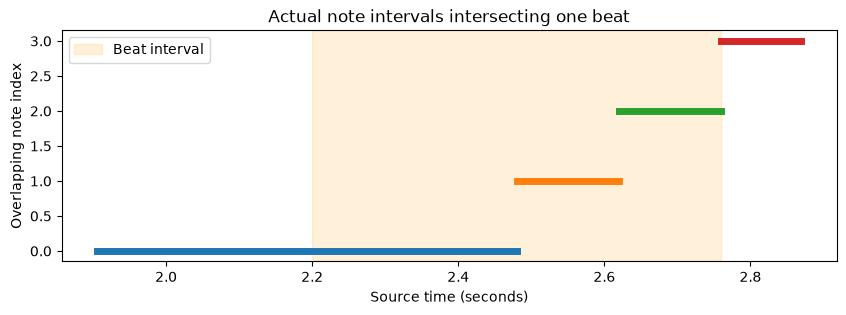

In [4]:
example=max(rows,key=lambda r:len(r['melody_midi']))
mel=melody_features(notes,example['start_sec'],example['end_sec'])
for key in ('melody_midi','melody_pitch_classes','melody_durations','melody_relative_start','melody_overlap_durations','melody_sources'):
    np.testing.assert_array_equal(mel[key],example[key])
print('Real demonstration beat:',example['beat_index'],'interval:',example['start_sec'],example['end_sec'])
table([{'note_index':i,'midi':p,'source':example['melody_sources'][i],
    'original_duration_sec':example['melody_durations'][i],'relative_onset_sec':example['melody_relative_start'][i],
    'overlap_sec':example['melody_overlap_durations'][i]} for i,p in enumerate(example['melody_midi'])])
fig,ax=plt.subplots(figsize=(10,3))
for i,note in enumerate(mel['melody']):ax.plot([note['onset_sec'],note['offset_sec']],[i,i],linewidth=5)
ax.axvspan(example['start_sec'],example['end_sec'],alpha=.15,color='orange',label='Beat interval')
ax.set(xlabel='Source time (seconds)',ylabel='Overlapping note index',title='Actual note intervals intersecting one beat');ax.legend();plt.show()

## 4. Detailed reference target: greatest overlap with ambiguity masking

The reference segment with greatest beat overlap wins; ties are deterministically ordered by source event ID. A target must have a parseable, supported normalized label, cover at least half the beat, and be unambiguous. The top two overlaps differing by at most 5% of beat duration makes the target ambiguous. Uncertain beats stay in the sequence but do not supervise the loss. `N` is a legitimate no-chord label, not padding.

Phase 1 `target_valid` checks alignment/support; Phase 2 additionally checks membership of the training-fitted target vocabulary. Thus `target_valid=True` does not by itself guarantee a supervised numerical target.

In [5]:
alignment=[]
for row in rows:
    best,candidates,ratio,ambiguous=align(row['start_sec'],row['end_sec'],chords)
    assert math.isclose(ratio,float(row['reference_overlap_ratio']),abs_tol=1e-12)
    assert ambiguous==(row['reference_ambiguous']=='True')
    alignment.append({'beat_index':row['beat_index'],'reference':row['reference_chord'],
        'overlap_ratio':ratio,'ambiguous':ambiguous,'phase1_target_valid':row['target_valid'],
        'encoded_target':int(encoder.encode_target(row)['target_chord_ids']),
        'loss_mask':bool(encoder.encode_target(row)['target_loss_mask']),'candidates':candidates})
table(alignment[:4]+[r for r in alignment if not r['phase1_target_valid']][:4])
print('All pilot alignment ratios/ambiguity decisions match reconstructed source alignment.')

beat_index,reference,overlap_ratio,ambiguous,phase1_target_valid,encoded_target,loss_mask,candidates
0,N,1.0,False,True,2,True,"[{""source_chord_event_id"": 0, ""chord"": ""N"", ""overlap_duration"": 0.47}]"
1,F:maj/3,0.8490566037735848,False,True,317,True,"[{""source_chord_event_id"": 1, ""chord"": ""F:maj/3"", ""overlap_duration"": 0.44999999999999996}, {""source_chord_event_id"": 0, ""chord"": ""N"", ""overlap_duration"": 0.08000000000000007}]"
2,F:maj/3,1.0,False,True,317,True,"[{""source_chord_event_id"": 1, ""chord"": ""F:maj/3"", ""overlap_duration"": 0.6000000000000001}]"
3,F:maj/3,1.0,False,True,317,True,"[{""source_chord_event_id"": 1, ""chord"": ""F:maj/3"", ""overlap_duration"": 0.5900000000000001}]"
147,F:maj,0.5208333333333445,True,False,-100,False,"[{""source_chord_event_id"": 27, ""chord"": ""F:maj"", ""overlap_duration"": 0.25}, {""source_chord_event_id"": 28, ""chord"": ""C:7"", ""overlap_duration"": 0.22999999999998977}]"
185,Bb:min,0.5000000000000148,True,False,-100,False,"[{""source_chord_event_id"": 35, ""chord"": ""Bb:min"", ""overlap_duration"": 0.2400000000000091}, {""source_chord_event_id"": 34, ""chord"": ""F:maj"", ""overlap_duration"": 0.23999999999999488}]"
259,D:maj,0.5208333333333136,True,False,-100,False,"[{""source_chord_event_id"": 48, ""chord"": ""D:maj"", ""overlap_duration"": 0.25}, {""source_chord_event_id"": 49, ""chord"": ""G:maj"", ""overlap_duration"": 0.2300000000000182}]"


All pilot alignment ratios/ambiguity decisions match reconstructed source alignment.


## 5. Canonicalization, detailed targets and synthetic basic-quality inputs

Equivalent roots in canonical chord labels are written consistently with sharps (`Db -> C#`, `Eb -> D#`, `Gb -> F#`, `Ab -> G#`, `Bb -> A#`). Detailed qualities and bass degrees remain in the target. Raw labels and audit fields stay available; not every categorical field is rewritten: for example, saved `basic_root` category tokens can still retain flat spellings.

Basic inputs deliberately simplify recognized reference pseudo-labels. This is a synthetic refinement task: `maj7` and `maj` can both yield the same basic major input. It is not evidence of performance on an independently predicted progression.

Quality rules: `maj*/6/add9 -> maj`; `min*/m/m6/m7/m9/m11/m13 -> min`; `7/9/11/13/7b9 -> dom`; `dim* -> dim`; `m7b5/co7/hdim/hdim7 -> hdim`; `aug*/+ -> aug`; `sus* -> sus`; `N -> N`. Half-diminished is checked before general minor/diminished handling. Unsupported source labels are retained for audit and masked as needed. Simplification support and detailed-target parsing support are separate decisions.

In [6]:
labels=['C:maj','C:6','C:maj7','C:maj9','C:add9','A:min','A:min7','A:min9','G:7','G:9','G:13','G:7b9','B:dim','B:dim7','B:hdim7','Bm7b5','Bco7','C:aug','C+','G:sus2','G:sus4','Eb:min7/b3','N']
quality_examples=[]
for label in labels:
    basic=simplify(label)
    try:canonical,_=canonicalize_chord(label)
    except ValueError:canonical='Unsupported canonical target'
    quality_examples.append({'reference_example':label,'canonical_target':canonical,**basic})
table(quality_examples)
assert simplify('C:maj7')['basic_chord']==simplify('C:maj')['basic_chord']
print('Actual saved basic-quality vocabulary:',encoder.vocabs['basic_quality'].tokens)
print('Full-chord target coordinates:',len(encoder.targets.tokens),'Special targets:',encoder.targets.tokens[:3])

reference_example,canonical_target,basic_chord,basic_root,basic_quality,simplification_status
C:maj,C:maj,C,C,maj,supported
C:6,C:6,C,C,maj,supported
C:maj7,C:maj7,C,C,maj,supported
C:maj9,C:maj9,C,C,maj,supported
C:add9,C:add9,C,C,maj,supported
A:min,A:min,Am,A,min,supported
A:min7,A:min7,Am,A,min,supported
A:min9,A:min9,Am,A,min,supported
G:7,G:7,G7,G,dom,supported
G:9,G:9,G7,G,dom,supported


Actual saved basic-quality vocabulary: ['PAD', 'UNK', 'N', 'START', 'END', 'unknown', 'aug', 'dim', 'dom', 'hdim', 'maj', 'min', 'sus']
Full-chord target coordinates: 402 Special targets: ['PAD', 'UNK', 'N']


## 6. Musical context, genres and progression neighbors

Key/mode and confidence come from available melody-key metadata. Roman numeral and harmonic function inputs are recomputed conservatively from the **basic** chord and key; the source reference Roman interpretation remains an audit field. Chromatic/unsupported interpretations can remain unknown. The `context()` implementation is deliberately conservative: it does not infer every extended chord's function.

Previous/next basic chords are taken from the complete original track. They cross bar/window boundaries, and START/END occur only at true track boundaries. Removing source events does not invent new progression neighbors. Genre tags are track-invariant multi-hot features. The 63-coordinate genre vector includes an UNK coordinate; held-out tags do not create new columns.

In [7]:
context_rows=[]
for r in rows[:6]:
    assert context(r,r['key'],r['mode'])==(r['roman_numeral'],r['harmonic_function'])
    context_rows.append({k:r[k] for k in ('beat_index','basic_chord','previous_basic_chord','next_basic_chord','key','mode','key_confidence','roman_numeral','harmonic_function','genre_tags')})
table(context_rows)
print('Raw source Roman audit row:');table(raw_romans[:1])
print('Input/target disjoint:',not bool(set(schema['input_columns']) & set(schema['target_columns'])))
assert not (set(schema['input_columns']) & FORBIDDEN_INPUTS)
print('Reference/audit fields are excluded by the encoder whitelist.')

beat_index,basic_chord,previous_basic_chord,next_basic_chord,key,mode,key_confidence,roman_numeral,harmonic_function,genre_tags
0,N,START,F,C,major,high,N,unknown,"[""classical""]"
1,F,N,F,C,major,high,IV,predominant,"[""classical""]"
2,F,F,F,C,major,high,IV,predominant,"[""classical""]"
3,F,F,F,C,major,high,IV,predominant,"[""classical""]"
4,F,F,F,C,major,high,IV,predominant,"[""classical""]"
5,F,F,F,C,major,high,IV,predominant,"[""classical""]"


Raw source Roman audit row:


track_id,start_sec,end_sec,original_chord_label,relative_root_semitones,relative_root,family,basic_label,mapping_status,bass_degree
382,0.0,0.56,N,,,N,N,no_chord,


Input/target disjoint: True
Reference/audit fields are excluded by the encoder whitelist.


## 7. All-track discovery and historical quality corrections

The pilot expanded to complete extraction tracks. The discovery function checks the six mandatory files and records each incomplete folder's missing inputs. Completeness is distinct from successful schema validation. Live discovery can differ if extraction files were added later; the historical discovery manifest is shown separately.

Historical quality rebuilds broadened basic-quality handling (v2), then introduced distinct dominant, half-diminished and augmented families (v3). Changes propagated into basic chord labels/IDs, previous/next chords, Roman/function context and the corresponding vocabularies and exports. Detailed target semantics were preserved. Never compare numerical category IDs across snapshots without their matching vocabulary.

In [8]:
V3=FINAL.parent/'final_all_tracks_quality_v3';V4=FINAL.parent/'final_all_tracks_quality_v4_m4'
historical_discovery=read_json(V3/'discovery_manifest.json')
live_discovery=discover(SOURCE)
table([{'inventory':name,'folders':len(items),**dict(Counter(r['status'] for r in items))} for name,items in [('Historical v3',historical_discovery),('Live source discovery',live_discovery)]])
table([r for r in historical_discovery if r['status']=='incomplete'][:4])
quality_rebuild=read_json(V3/'quality_rebuild_validation.json')
print('Recorded historical v3 changed-column counts:');table([{'column':k,'changed_positions':v} for k,v in quality_rebuild['source_changed_columns'].items()])
print('Recorded real corrected examples:');table(quality_rebuild['corrected_examples'][:5])
print('Final validated track count:',sum(v['tracks'] for v in stats.values()))

inventory,folders,candidate,incomplete
Historical v3,1156,525,631
Live source discovery,1156,525,631


track_id,source_folder,status,missing_files
917544,track_0917544,incomplete,"[""melody/combined.csv"", ""roman/full.csv"", ""beats/beats.csv"", ""beats/beats.json""]"
918148,track_0918148,incomplete,"[""melody/combined.csv"", ""roman/full.csv"", ""beats/beats.csv"", ""beats/beats.json""]"
919931,track_0919931,incomplete,"[""melody/combined.csv"", ""roman/full.csv"", ""beats/beats.csv"", ""beats/beats.json""]"
920193,track_0920193,incomplete,"[""melody/combined.csv"", ""roman/full.csv"", ""beats/beats.csv"", ""beats/beats.json""]"


Recorded historical v3 changed-column counts:


column,changed_positions
next_basic_chord,8274
basic_chord,8280
basic_quality,8280
basic_chord_canonical,8280
roman_numeral,2211
harmonic_function,1464
previous_basic_chord,8279
simplification_status,161
basic_root_pitch_class,161


Recorded real corrected examples:


track_id,beat_index,reference_chord,old_basic_quality,new_basic_quality,old_basic_quality_id,new_basic_quality_id,old_basic_chord,new_basic_chord
382,43,C:7,maj,dom,7,8,C,C7
382,275,G:7,maj,dom,7,8,G,G7
382,280,D:7,maj,dom,7,8,D,D7
387,6,Ab:7,maj,dom,7,8,Ab,Ab7
387,32,F:7,maj,dom,7,8,F,F7


Final validated track count: 525


## 8. The 99-note trailing-window outlier and historical m4 experiment

The outlier was not a normal beat with 99 simultaneous notes. The final detected beat extended to the end of the audio, producing an unusually long interval. The whole containing eight-position sequence was excluded without repacking. Four positions were real beats; four were padding.

The historical v4 m4 snapshot then kept only the first four notes per beat in source order. That policy discarded note occurrences and was later abandoned. The v5 rebuild recovered full notes from the **original Phase 1 event CSVs**, not from truncated v4 tensors. Its note capacity was the retained training maximum rounded up to a power of two: observed 18 -> capacity 32. Held-out overflow fails explicitly; the test set does not fit this capacity. Final data has no four-note limit and no note truncation on retained beats.

track_id,beat_index,start_sec,end_sec,duration_sec,overlapping_notes,median_other_beat_sec
572381,667,197.26,250.0,52.74000000000001,99,0.29999999999999716


beat_index,start_sec,end_sec,event_duration,notes
664,196.36,196.66,0.29999999999998295,2
665,196.66,196.96,0.30000000000001137,2
666,196.96,197.26,0.29999999999998295,2
667,197.26,250.0,52.74000000000001,99


Historical four-slot note occurrences discarded:

 4400
Current capacity policy: Training maximum rounded up to power of two; retain every source note. Fail on held-out overflow instead of truncating or fitting capacity on test data.


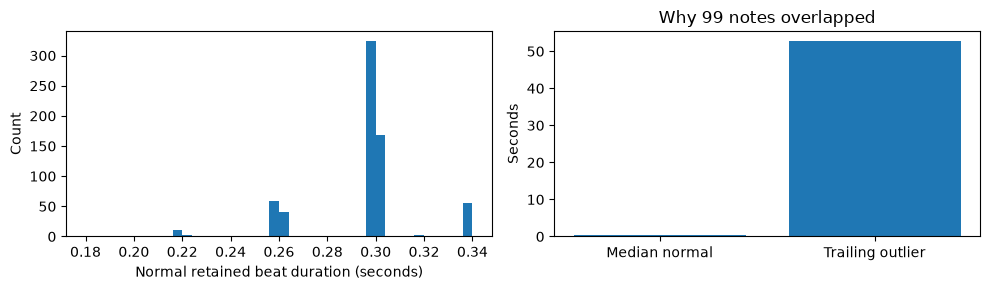

In [9]:
exclusion=read_json(FINAL/'outlier_exclusion.json')
OUT=exclusion['track_id'];out_name=f'track_{int(OUT):07d}'
out_rows,_=load_events(PHASE1/out_name/f'{out_name}_training_events.csv')
outlier=next(r for r in out_rows if r['beat_index']==exclusion['outlier_beat_index'])
kept,removed=remove_outlier_window(out_rows,OUT,exclusion['outlier_beat_index'],exclusion['sequence_length'])
assert [r['beat_index'] for r in removed]==exclusion['removed_beat_indices']
assert len(outlier['melody_midi'])==exclusion['outlier_note_count']
ordinary_durations=[r['event_duration'] for r in kept]
table([{'track_id':OUT,'beat_index':outlier['beat_index'],'start_sec':outlier['start_sec'],'end_sec':outlier['end_sec'],
    'duration_sec':outlier['event_duration'],'overlapping_notes':len(outlier['melody_midi']),
    'median_other_beat_sec':float(np.median(ordinary_durations))}])
table([{k:r[k] for k in ('beat_index','start_sec','end_sec','event_duration')}|{'notes':len(r['melody_midi'])} for r in removed])
v4stats=read_json(V4/'preprocessing_statistics.json')
print('Historical four-slot note occurrences discarded:',sum(s['notes_truncated'] for s in v4stats.values()))
print('Current capacity policy:',settings['note_capacity_policy'])
assert encoder.max_notes==1 << (settings['observed_training_max_notes']-1).bit_length()
assert not encoder.truncate
fig,axes=plt.subplots(1,2,figsize=(10,3))
axes[0].hist(ordinary_durations,bins=40);axes[0].set(xlabel='Normal retained beat duration (seconds)',ylabel='Count')
axes[1].bar(['Median normal','Trailing outlier'],[np.median(ordinary_durations),outlier['event_duration']]);axes[1].set(ylabel='Seconds',title='Why 99 notes overlapped')
plt.tight_layout();plt.show()

## 9. Bar integrity, exact exclusions and retained coverage

v5 grouped each sequence by source bar and excluded seven malformed bars with invalid position/meter metadata. The exclusion report records actual reasons and exact beat IDs. Valid partial bars were retained and flagged.

v6 inherits those exclusions plus the outlier window. It introduces no further lost or duplicated eligible events. A source-meter count disagreement is not automatically an exclusion. Partial/uncertain boundaries and irregular source meters are separate flags; source bars are not corrected by fabricating beats.

In [10]:
grouping=read_json(FINAL/'bar_grouping_report.json')
invalid_bars=grouping['invalid_bars_excluded']
bar_excluded_count=sum(len(b['beat_indices']) for b in invalid_bars)
table(invalid_bars)
reconciliation={'raw_beats':validation['raw_source_beats'],'outlier_removed_real_beats':len(removed),
    'malformed_bar_removed_beats':bar_excluded_count,'eligible_beats':sum(s['real_beats'] for s in stats.values()),
    'new_v6_lost':validation['source_beats_lost'],'new_v6_duplicates':validation['source_beats_duplicated']}
assert reconciliation['raw_beats']-len(removed)-bar_excluded_count==reconciliation['eligible_beats']
table([reconciliation])
ids=[t for assigned in split_manifest['splits'].values() for t in assigned]
validate_splits(split_manifest,ids)
tracks=BarTracks(PHASE1,ids,OUT,exclusion['outlier_beat_index'],exclusion['sequence_length'])
tracks.excluded_bars={}
for bar in invalid_bars:tracks.excluded_bars.setdefault(bar['track_id'],set()).add(bar['bar_number'])
print('Current preprocessing loader reconstructs retained events from original full-melody Phase 1 CSVs.')

track_id,bar_number,beat_indices,beat_positions,reasons
207501,25,"[100, 101, 102, 103, 104]","[1, 2, 3, 4, 4]","[""duplicate or decreasing beat positions""]"
603757,51,"[189, 190, 191, 192, 193]","[1, 2, 3, 4, 4]","[""duplicate or decreasing beat positions""]"
628409,53,"[203, 204, 205, 206, 207, 208, 209]","[1, 2, 3, 4, 2, 3, 4]","[""duplicate or decreasing beat positions""]"
801443,39,"[156, 157, 158, 159, 160]","[1, 2, 3, 4, 4]","[""duplicate or decreasing beat positions""]"
43886,46,"[178, 179, 180, 181, 182]","[1, 2, 3, 4, 4]","[""duplicate or decreasing beat positions""]"
678176,25,"[99, 100, 101, 102, 103]","[1, 2, 3, 4, 4]","[""duplicate or decreasing beat positions""]"
901684,37,"[146, 147, 148, 149, 150, 151, 152]","[1, 2, 3, 4, 2, 3, 4]","[""duplicate or decreasing beat positions""]"


raw_beats,outlier_removed_real_beats,malformed_bar_removed_beats,eligible_beats,new_v6_lost,new_v6_duplicates
212212,4,39,212169,0,0


Current preprocessing loader reconstructs retained events from original full-melody Phase 1 CSVs.


## 10. Group splits before fitting vocabularies

Tracks sharing available artist, album or recording-path identities form connected groups. Entire groups are assigned with local seeded randomness, not individual beats. The 80/10/10 request applies to numbers of identity groups, so actual track proportions differ. Grouping protects against known metadata overlap; it is not audio-fingerprint duplicate detection.

The encoder fits categories and detailed targets on retained **training** events only. Validation/test never expand these mappings. Input unknowns use UNK; unseen/unsupported or uncertain targets use -100 and false loss masks. N remains a supervised musical target. Current v6 reuses the exact v5 training-fitted mappings because the retained beat population is unchanged.

In [11]:
assert set(encoder.training_tracks)==set(split_manifest['splits']['train'])
owner={t:s for s,assigned in split_manifest['splits'].items() for t in assigned}
assert all(len({owner[t] for t in group})==1 for group in split_manifest['identity_groups'])
table([{'split':s,'tracks':len(assigned),'actual_track_fraction':len(assigned)/len(ids)} for s,assigned in split_manifest['splits'].items()])
print('Split policy:',split_manifest['policy']);print('Seed:',split_manifest['seed'],'Requested ratios:',split_manifest['requested_ratios'])
table([{'identity_group_tracks':g,'split':owner[g[0]],'sample_identities':split_manifest.get('identities',{}).get(g[0],[])[:3]} for g in sorted(split_manifest['identity_groups'],key=len,reverse=True)[:4]])
table([{'feature':field,'vocabulary_size':len(v.tokens),'reserved_prefix':v.tokens[:6]} for field,v in encoder.vocabs.items()])
print('Target vocabulary:',len(encoder.targets.tokens),'coordinates; prefix:',encoder.targets.tokens[:3])
print('Genre coordinates:',len(encoder.genres),'including',encoder.genres[0])
print('Example unseen input:',encoder.vocabs['key'].encode('__never_seen__'))
unknown_target={**rows[0],'target_valid':True,'reference_chord':'C:future_unsupported','reference_chord_canonical':'C:future_unsupported'}
print('Illustrative unsupported target (in-memory only):',encoder.encode_target(unknown_target))

split,tracks,actual_track_fraction
train,470,0.8952380952380953
validation,23,0.04380952380952381
test,32,0.06095238095238095


Split policy: Shuffle recording/artist connected groups with local seeded RNG; round group counts and preserve nonempty requested subsets. Actual track ratios may differ.
Seed: 42 Requested ratios: [0.8, 0.1, 0.1]


identity_group_tracks,split,sample_identities
"[""556349"", ""556350"", ""556351"", ""556352"", ""556353"", ""556354"", ""556355"", ""556357"", ""556370"", ""556372"", ""556373"", ""556375"", ""556376"", ""556377"", ""556378"", ""556379"", ""556383"", ""565788"", ""565789"", ""565790"", ""565792"", ""565793"", ""565794"", ""565795"", ""565796"", ""565797"", ""565798"", ""565799"", ""565800"", ""565801"", ""565802"", ""565803"", ""565804"", ""565805"", ""565806"", ""565807"", ""565808"", ""565809"", ""565810"", ""571472"", ""571473"", ""571474"", ""571475"", ""571476"", ""571477"", ""571478"", ""571479"", ""571480"", ""571481"", ""571482"", ""571483"", ""571484"", ""571485"", ""571486"", ""571487"", ""571488"", ""571489"", ""571490"", ""585146"", ""585147"", ""585148"", ""585149"", ""585150"", ""585151"", ""585152"", ""585153"", ""585154"", ""585155"", ""585156"", ""585157"", ""585158"", ""659885"", ""659886"", ""659887"", ""659888"", ""659889"", ""659890"", ""659891"", ""659892"", ""659893"", ""659894"", ""659895"", ""659896"", ""659897"", ""659898"", ""659899"", ""659900"", ""659901"", ""659902"", ""659903"", ""659904"", ""802274"", ""802275"", ""802276"", ""802277"", ""802278"", ""802279"", ""802280"", ""802281"", ""802282"", ""802283"", ""802284"", ""802285""]",train,"[""artist:artist_359034"", ""album:album_064662"", ""recording:vocal-tagged-audio/49/556349.low.mp3""]"
"[""207461"", ""207464"", ""207469"", ""207471"", ""207490"", ""207501"", ""207506"", ""207517"", ""207532"", ""207545"", ""207562"", ""207564"", ""215555"", ""215560"", ""215561"", ""215566"", ""215567"", ""230767"", ""230805"", ""230823"", ""230830"", ""230839"", ""230843"", ""230860"", ""230871"", ""230885"", ""230889"", ""230903"", ""230905"", ""644846"", ""644847"", ""679017"", ""679018"", ""785267"", ""785281"", ""854720"", ""854721"", ""915578"", ""915579"", ""915580"", ""915581"", ""915582"", ""915584"", ""915676"", ""915677"", ""915737"", ""915738"", ""915739"", ""915740""]",train,"[""artist:artist_341393"", ""album:album_030719"", ""recording:vocal-tagged-audio/61/207461.low.mp3""]"
"[""345139"", ""345140"", ""345141"", ""345143"", ""345144"", ""345145"", ""345154"", ""345155"", ""345156"", ""345157"", ""345158"", ""347847"", ""347851"", ""347854"", ""347858"", ""347859"", ""347861"", ""347879"", ""356417"", ""356418"", ""356420"", ""356422"", ""356423"", ""356426"", ""356427"", ""356441"", ""356443"", ""356447"", ""832631"", ""832632"", ""832633"", ""832634""]",train,"[""artist:artist_340710"", ""album:album_045452"", ""recording:vocal-tagged-audio/39/345139.low.mp3""]"
"[""31424"", ""31425"", ""31426"", ""31427"", ""31428"", ""31429"", ""31430"", ""31431"", ""31432"", ""31433"", ""31434"", ""31435"", ""31436"", ""603750"", ""603751"", ""603752"", ""603753"", ""603754"", ""603755"", ""603756"", ""603757"", ""603758"", ""603759"", ""603760"", ""603761"", ""603762""]",train,"[""artist:artist_002485"", ""album:album_003929"", ""recording:vocal-tagged-audio/24/31424.low.mp3""]"


feature,vocabulary_size,reserved_prefix
basic_chord_canonical,82,"[""PAD"", ""UNK"", ""N"", ""START"", ""END"", ""unknown""]"
basic_quality,13,"[""PAD"", ""UNK"", ""N"", ""START"", ""END"", ""unknown""]"
basic_root,18,"[""PAD"", ""UNK"", ""N"", ""START"", ""END"", ""unknown""]"
harmonic_function,9,"[""PAD"", ""UNK"", ""N"", ""START"", ""END"", ""unknown""]"
key,18,"[""PAD"", ""UNK"", ""N"", ""START"", ""END"", ""unknown""]"
key_confidence,10,"[""PAD"", ""UNK"", ""N"", ""START"", ""END"", ""unknown""]"
mode,8,"[""PAD"", ""UNK"", ""N"", ""START"", ""END"", ""unknown""]"
next_basic_chord,82,"[""PAD"", ""UNK"", ""N"", ""START"", ""END"", ""unknown""]"
previous_basic_chord,82,"[""PAD"", ""UNK"", ""N"", ""START"", ""END"", ""unknown""]"
roman_numeral,18,"[""PAD"", ""UNK"", ""N"", ""START"", ""END"", ""unknown""]"


Target vocabulary: 402 coordinates; prefix: ['PAD', 'UNK', 'N']
Genre coordinates: 63 including UNK
Example unseen input: 1
Illustrative unsupported target (in-memory only): {'target_chord_ids': np.int64(-100), 'target_loss_mask': np.False_}


## 11. Numerical encoding: all stored features and exact melody formulas

Integer IDs are categorical identifiers, not numerical distances. Current chord, root/quality, neighbors, key/mode/confidence, Roman/function and melody source vocabularies must travel with their tensors.

For each real note:
- `melody_pitch_ids = round(fractional_MIDI) + 2` (Python nearest integer, ties to even); 0 is PAD, 1 is reserved UNK.
- `melody_pitch_values = fractional_MIDI / 127`, stored float32; pitch-class tokens are source integer pitch class + 2.
- `melody_timing = [original_duration, relative_onset, overlap_duration] / beat_duration`, float32.

Relative onset can be negative and original duration ratios can exceed 1. These are not clipped. Genre is a sequence-level multi-hot vector because it is invariant within a track. Beat/bar/duration values are float32 source values with separate known-value flags. No dataset-wide learned numerical scaler is fitted. Relative bar number is recomputed when constructing each window.

All stored tensors are enumerated below, including features later omitted from model inputs.

In [12]:
encoded=encoder.encode_inputs(example['input_snapshot'])
table([{'field':k,'shape':list(np.asarray(v).shape),'dtype':str(np.asarray(v).dtype)} for k,v in encoded.items()])
note_view=[]
for i,pitch in enumerate(example['melody_midi']):
    expected=np.asarray([example['melody_durations'][i],example['melody_relative_start'][i],example['melody_overlap_durations'][i]])/example['event_duration']
    np.testing.assert_array_equal(encoded['melody_timing'][i],expected.astype(np.float32))
    assert encoded['melody_pitch_ids'][i]==round(pitch)+2
    note_view.append({'note':i,'fractional_MIDI':pitch,'pitch_token':int(encoded['melody_pitch_ids'][i]),
        'normalized_pitch':float(encoded['melody_pitch_values'][i]),'pitch_class_token':int(encoded['melody_pitch_class_ids'][i]),
        'timing_duration_onset_overlap':encoded['melody_timing'][i].tolist(),'real_note':bool(encoded['melody_note_mask'][i])})
table(note_view)
print('Active genre tags:',[g for g,v in zip(encoder.genres,encoded['genre_features']) if v])
print('Known timing-mask order: [bar_number known, beat_position known]')

field,shape,dtype
basic_chord_ids,[],int64
basic_root_ids,[],int64
basic_quality_ids,[],int64
previous_basic_chord_ids,[],int64
next_basic_chord_ids,[],int64
key_ids,[],int64
mode_ids,[],int64
key_confidence_ids,[],int64
roman_ids,[],int64
harmonic_function_ids,[],int64


note,fractional_MIDI,pitch_token,normalized_pitch,pitch_class_token,timing_duration_onset_overlap,real_note
0,65.0,67,0.5118110179901123,7,"[1.0267857313156128, -0.526410698890686, 0.500374972820282]",True
1,65.0,67,0.5118110179901123,7,"[0.24924999475479126, 0.500374972820282, 0.24924999475479126]",True
2,65.0,67,0.5118110179901123,7,"[0.2501964271068573, 0.749625027179718, 0.2501964271068573]",True
3,65.0,67,0.5118110179901123,7,"[0.1962321400642395, 0.9998214244842529, 0.00017857142665889114]",True


Active genre tags: ['classical']
Known timing-mask order: [bar_number known, beat_position known]


## 12. Separate masks: real beats, real notes, safe attention and supervision

| Situation | Beat attention | Real-note mask | Target loss |
|---|---|---|---|
| Real beat with valid known target | True | Actual notes True | True |
| Real silent beat with valid target | True | All False | True |
| Real ambiguous/unsupported/unseen target | True | Actual notes | False |
| Artificial batch padding | False | All False | False |

`melody_silent` marks beats with no notes. The stored `melody_attention_mask` gives even a silent beat a safe dummy slot, while its real-note mask remains false. This prevents all-masked note attention without claiming a dummy note is real. Beat-padding targets are -100. For a PyTorch API expecting True for ignored keys, use `key_padding_mask = ~beat_attention_mask`; the project's custom attention receives its existing True-means-real convention.

Input/target/audit roles are enforced by a whitelist and an input snapshot. This prevents direct target-field leakage into encoder tensors. It does **not** erase the explicitly documented synthetic dependency of basic chords on reference labels.

In [13]:
silent=next((r for r in rows if not r['melody_midi']),None)
if silent is None:
    silent=copy.deepcopy(rows[0])
    for field in ('melody_midi','melody_pitch_classes','melody_durations','melody_relative_start','melody_overlap_durations','melody_sources'):silent[field]=[]
    silent['input_snapshot']={k:silent[k] for k in USED_INPUTS}
    print('No silent pilot event; illustrative silence projection only.')
silent_encoded=encoder.encode_inputs(silent['input_snapshot'])
assert not silent_encoded['melody_note_mask'].any() and silent_encoded['melody_attention_mask'][0]
assert silent_encoded['melody_silent']
table([{'case':'Real silent beat','real_notes':int(silent_encoded['melody_note_mask'].sum()),
    'safe_attention_slots':int(silent_encoded['melody_attention_mask'].sum()),'melody_silent':bool(silent_encoded['melody_silent'])}])
changed=copy.deepcopy(example)
for field in ('reference_chord','reference_chord_canonical','reference_quality','source_roman','reference_candidates'):changed[field]='changed_target_audit_only'
for k,v in encoder.encode_inputs(changed).items():np.testing.assert_array_equal(v,encoder.encode_inputs(example)[k])
print('Changing reference/audit fields leaves every encoder input identical. Synthetic-basic provenance remains documented.')

case,real_notes,safe_attention_slots,melody_silent
Real silent beat,0,1,True


Changing reference/audit fields leaves every encoder input identical. Synthetic-basic provenance remains documented.


## 13. One-bar v5 to four-bar variable-length v6

The historical eight-beat windows did not respect musical bars. v5 changed to one source bar per sequence (with storage capacity nine beat positions). v6 now groups up to four consecutive source bars, with one actual beat per token and no global beat padding.

Four regular 4/4 bars can yield 16 tokens; four regular three-beat bars can yield 12. Actual retained source events determine lengths, never a forced 16 or solely a meter numerator. Source gaps break windows, internal partial bars are isolated, opening/ending partial bars and final short windows remain. Boundaries use position/downbeat/timing checks. Meter disagreement and uncertain boundaries are retained audit flags.

Previous/next basics retain original track neighbors. Relative bar offsets restart within each new window. The following reconstructs Track 382 using the same source-meter ending-bar check used by the v6 builder, then compares **every numerical tensor for that track** against the saved v6 shard.

In [14]:
retained=tracks[TRACK]
raw_lookup={int(r['beat_index']):r for r in raw_beats}
for event in retained:event['source_meter_disagreement']=(TRACK,event['bar_number']) in {(str(b['track_id']),int(b['bar_number'])) for b in grouping['partial_bars']}
last_bar=[r for r in retained if r['bar_number']==retained[-1]['bar_number']]
meter=raw_lookup[last_bar[-1]['beat_index']]
durations=[r['event_duration'] for r in last_bar]
import statistics
retained[-1]['bar_end_confirmed']=(last_bar[0]['beat_position']==1 and [r['beat_position'] for r in last_bar]==list(range(1,int(meter['meter_numerator'])+1)) and durations[-1]<=1.75*statistics.median(durations[:-1] or durations))
rebuilt=ChordSequenceDataset({TRACK:retained},encoder,sequence_unit='multi_bar',bars_per_sequence=settings['bars_per_sequence'])
track_split=owner[TRACK]
saved_pilot=SavedSequenceDataset(FINAL/f'{track_split}_sequences/{NAME}.npz')
assert len(rebuilt)==len(saved_pilot)
for i in range(len(rebuilt)):
    a,b=rebuilt[i],saved_pilot[i]
    for group in ('inputs','targets'):
        assert a[group].keys()==b[group].keys()
        for key in a[group]:torch.testing.assert_close(a[group][key],b[group][key],rtol=0,atol=0)
    assert torch.equal(a['metadata']['beat_indices'],b['metadata']['beat_indices'])
print('Reconstructed and exactly compared all Track 382 sequences:',len(rebuilt))
manifest=read_csv(FINAL/'sequence_manifest.csv')
table([r for r in manifest if r['track_id']==TRACK][:4])
table([r for r in manifest if r['contains_partial_bar']=='True'][:3])
issues=read_json(FINAL/'sequence_issues.json')
print('Boundary/issue policy:',issues['policy'])
print('Recorded window reasons:',dict(Counter(r['window_reason'] for r in manifest)))
print('Partial/uncertain bars:',sum(v['partial_bars'] for v in stats.values()),'Irregular bars:',sum(v['irregular_bars'] for v in stats.values()))

Reconstructed and exactly compared all Track 382 sequences: 27


split,track_id,sequence_id,sequence_start_bar,sequence_end_bar,bars_in_sequence,real_beats_in_sequence,first_beat_index,last_beat_index,start_sec,end_sec,source_meters,valid_targets,invalid_targets,final_partial_window,complete_bar_count,complete_bar_window,contains_partial_bar,contains_irregular_bar,partial_bars_count,irregular_bars_count,window_reason
train,382,3182,0,3,4,16,0,15,0.01,8.2,"[""4/4""]",16,0,False,4,True,False,False,0,0,full_bar_window
train,382,3183,4,7,4,16,16,31,8.2,16.48,"[""4/4""]",16,0,False,4,True,False,False,0,0,full_bar_window
train,382,3184,8,11,4,16,32,47,16.48,25.16,"[""4/4""]",16,0,False,4,True,False,False,0,0,full_bar_window
train,382,3185,12,15,4,16,48,63,25.16,33.44,"[""4/4""]",16,0,False,4,True,False,False,0,0,full_bar_window


split,track_id,sequence_id,sequence_start_bar,sequence_end_bar,bars_in_sequence,real_beats_in_sequence,first_beat_index,last_beat_index,start_sec,end_sec,source_meters,valid_targets,invalid_targets,final_partial_window,complete_bar_count,complete_bar_window,contains_partial_bar,contains_irregular_bar,partial_bars_count,irregular_bars_count,window_reason
train,126041,29,100,100,1,3,396,398,298.44,300.0,"[""4/4""]",3,0,True,0,False,True,True,1,1,track_end
train,126047,58,112,113,2,7,443,449,217.6,220.500658,"[""4/4""]",7,0,True,1,False,True,True,1,1,track_end
train,126061,145,108,110,3,11,432,442,277.81,284.997596,"[""4/4""]",11,0,True,2,False,True,True,1,1,track_end


Boundary/issue policy: Retain partial opening/ending bars and final short windows. Isolate internal partial bars. Break windows at excluded-bar/beat/time gaps; never bridge them.


Recorded window reasons: {'full_bar_window': 14115, 'track_end': 398, 'source_gap': 7, 'before_internal_partial_bar': 1, 'internal_partial_bar_retained': 1}
Partial/uncertain bars: 430 Irregular bars: 1589


## 14. Ragged storage: concatenated beats and sequence offsets

The primary split file is a JSON index (`train_sequences.json`, `validation_sequences.json`, `test_sequences.json`) pointing to per-track NPZ shards. Each shard concatenates only real beats; int64 `sequence_offsets` delimit sequences. A sequence spans `offsets[i]:offsets[i+1]`. Genres are stored per sequence, not duplicated per beat in NPZ. Metadata has its own arrays. All NPZ arrays load with `allow_pickle=False`; no object/pickle arrays are required.

SavedSequenceDataset reads the index and shards. The old global fixed-shape NPZ file is not the primary v6 training entry point. Use the matching saved vocabularies with these indices.

In [15]:
indices={s:read_json(FINAL/f'{s}_sequences.json') for s in split_manifest['splits']}
first_shard=FINAL/indices['train']['shards'][0]['path']
with np.load(first_shard,allow_pickle=False) as z:
    table([{'array':k,'shape':list(z[k].shape),'dtype':str(z[k].dtype)} for k in z.files])
    offsets=z['sequence_offsets'];assert offsets.dtype==np.int64 and offsets[0]==0
    table([{'local_sequence':i,'start_offset':int(a),'end_offset':int(b),'real_beats':int(b-a)} for i,(a,b) in enumerate(zip(offsets,offsets[1:]))])
    assert int(offsets[-1])==len(z['inputs__beat_attention_mask'])
datasets={s:SavedSequenceDataset(FINAL/f'{s}_sequences.json') for s in indices}
print('Loader source:',inspect.getfile(SavedSequenceDataset))

array,shape,dtype
inputs__basic_chord_ids,[64],int64
inputs__basic_root_ids,[64],int64
inputs__basic_quality_ids,[64],int64
inputs__previous_basic_chord_ids,[64],int64
inputs__next_basic_chord_ids,[64],int64
inputs__key_ids,[64],int64
inputs__mode_ids,[64],int64
inputs__key_confidence_ids,[64],int64
inputs__roman_ids,[64],int64
inputs__harmonic_function_ids,[64],int64


local_sequence,start_offset,end_offset,real_beats
0,0,16,16
1,16,32,16
2,32,48,16
3,48,64,16


Loader source: C:\Users\srjay\OneDrive\Desktop\Research\vocal-harmonization\experiments\rahul\src\transformer_dataset.py


## 15. Dynamic padding at batch load time

Only the current batch is padded to its longest sequence. The example below selects real saved lengths 12, 16 and 20, then shows decoded chords and masks side by side, including artificial positions. The note dimension remains 32 slots; variable-length beats and padded note slots are two different dimensions.

Genre shape is `[B,G]`; chord/target shape `[B,L]`; pitch/mask `[B,L,M]`; timing `[B,L,M,3]`. Padded targets are -100 with false loss masks. Real ambiguous beats keep true beat attention and false target loss. Different batch sizes/orderings change padding overhead. The saved-order batch-size-four overhead reported in the historical build is not a universal training ratio.

group,tensor,shape,dtype
inputs,basic_chord_ids,"[3, 20]",torch.int64
inputs,basic_root_ids,"[3, 20]",torch.int64
inputs,basic_quality_ids,"[3, 20]",torch.int64
inputs,previous_basic_chord_ids,"[3, 20]",torch.int64
inputs,next_basic_chord_ids,"[3, 20]",torch.int64
inputs,key_ids,"[3, 20]",torch.int64
inputs,mode_ids,"[3, 20]",torch.int64
inputs,key_confidence_ids,"[3, 20]",torch.int64
inputs,roman_ids,"[3, 20]",torch.int64
inputs,harmonic_function_ids,"[3, 20]",torch.int64


example,track_id,position,real_length,basic_chord,target,beat_attention,note_count,silent,loss_mask
0,126047,0,12,G,G:maj,True,2,False,True
0,126047,1,12,A,A:maj,True,3,False,True
0,126047,2,12,A,A:maj,True,3,False,True
0,126047,3,12,A,A:maj,True,3,False,True
0,126047,4,12,A,A:maj,True,2,False,True
0,126047,5,12,A,A:maj,True,3,False,True
0,126047,6,12,A,A:maj,True,1,False,True
0,126047,7,12,A,A:maj,True,2,False,True
0,126047,8,12,G,G:maj,True,2,False,True
0,126047,9,12,G,G:maj,True,2,False,True


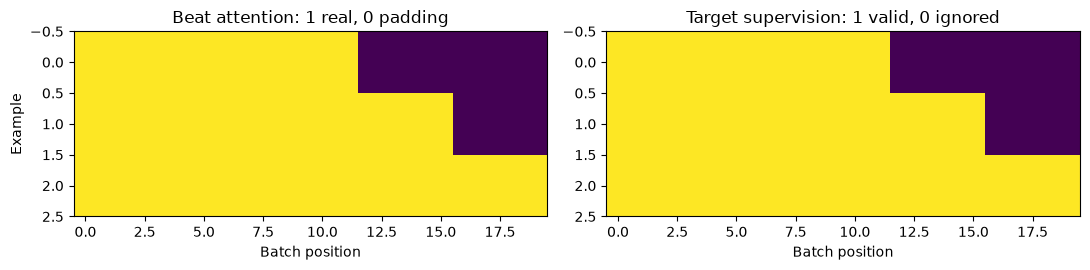

In [16]:
examples=[]
for length in (12,16,20):
    entry=next(r for r in manifest if int(r['real_beats_in_sequence'])==length)
    examples.append(datasets[entry['split']][int(entry['sequence_id'])])
batch=collate_sequences(examples)
table([{'group':group,'tensor':k,'shape':list(v.shape),'dtype':str(v.dtype)} for group in ('inputs','targets') for k,v in batch[group].items()])
mask_rows=[]
for b,item in enumerate(examples):
    length=len(item['inputs']['beat_attention_mask'])
    for t in range(batch['inputs']['beat_attention_mask'].shape[1]):
        target=int(batch['targets']['target_chord_ids'][b,t]);basic=int(batch['inputs']['basic_chord_ids'][b,t])
        mask_rows.append({'example':b,'track_id':item['metadata']['track_id'],'position':t,'real_length':length,
            'basic_chord':encoder.vocabs['basic_chord_canonical'].decode(basic),
            'target':encoder.targets.decode(target) if target>=0 else 'IGNORE',
            'beat_attention':bool(batch['inputs']['beat_attention_mask'][b,t]),
            'note_count':int(batch['inputs']['melody_note_mask'][b,t].sum()),
            'silent':bool(batch['inputs']['melody_silent'][b,t]),'loss_mask':bool(batch['targets']['target_loss_mask'][b,t])})
table(mask_rows)
padding=~batch['inputs']['beat_attention_mask']
assert (batch['targets']['target_chord_ids'][padding]==-100).all()
assert not batch['targets']['target_loss_mask'][padding].any()
fig,axes=plt.subplots(1,2,figsize=(11,2.8))
axes[0].imshow(batch['inputs']['beat_attention_mask'],aspect='auto',vmin=0,vmax=1);axes[0].set(title='Beat attention: 1 real, 0 padding',xlabel='Batch position',ylabel='Example')
axes[1].imshow(batch['targets']['target_loss_mask'],aspect='auto',vmin=0,vmax=1);axes[1].set(title='Target supervision: 1 valid, 0 ignored',xlabel='Batch position');plt.tight_layout();plt.show()

## 16. Dataset-wide live coverage, masks, melody capacity and label counts

This cell reads every current shard, verifies offset/beat coverage and target-mask consistency, calculates split totals and melody-note maxima from numerical arrays, and builds detailed-target frequencies. It does not refit anything. Detailed-class imbalance is observable here; class weighting and multi-task supervision belong to later model experiments, not to the immutable preprocessing snapshot.

The v6 saved population should reconcile with the source/exclusion ledger. Source bar counts and irregularity flags come from metadata reports; the numerical scan independently verifies beats, sequences, targets and notes.

Fresh counts from every shard:


split,tracks,sequences,real_beats,valid_targets,invalid_targets,silent_beats,max_actual_notes
train,470,12718,186572,184867,1705,25052,18
validation,23,814,11319,11214,105,1170,7
test,32,990,14278,14077,201,1810,6


reference_quality,train,validation,test
7,7409,85,325
9,101,0,0
N,14904,907,1112
aug,39,0,8
dim,259,2,7
dim7,2,0,0
hdim7,230,0,0
maj,79843,6046,5040
maj7,3284,95,926
min,61655,3591,5019


Actual sequence length min/max/mean: 1 24 14.610177661479135


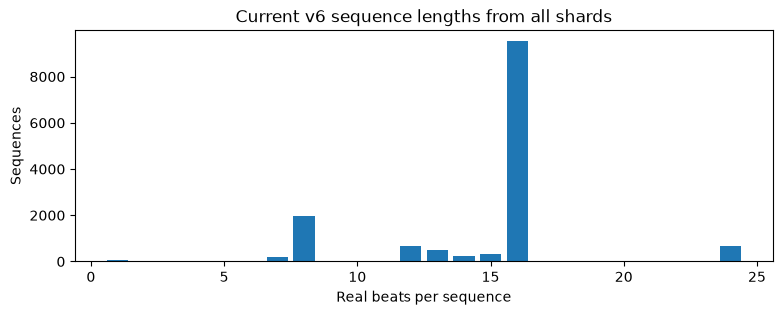

In [17]:
live_totals=[];length_counts=Counter();quality_counts={};max_notes_by_split={}
from experiments.rahul.src.normalize_chords import parse_chord_label
for split,index in indices.items():
    nseq=nbeat=nvalid=nsilent=0;max_notes=0;freq=np.zeros(len(encoder.targets.tokens),dtype=np.int64)
    for shard in index['shards']:
        with np.load(FINAL/shard['path'],allow_pickle=False) as z:
            offsets=z['sequence_offsets'];lengths=np.diff(offsets);beats=z['beat_indices'];attn=z['inputs__beat_attention_mask']
            assert offsets[0]==0 and offsets[-1]==len(beats) and (lengths>0).all()
            assert len(np.unique(beats))==len(beats) and (np.diff(beats)>0).all() and attn.all()
            assert len(lengths)==shard['sequences'] and len(beats)==shard['real_beats']
            target=z['targets__target_chord_ids'];valid=z['targets__target_loss_mask']
            assert (target[~valid]==-100).all() and ((target[valid]>=2)&(target[valid]<len(freq))).all()
            nm=z['inputs__melody_note_mask'];silent=z['inputs__melody_silent']
            assert nm.shape[1]==encoder.max_notes and np.array_equal(~nm.any(1),silent)
            max_notes=max(max_notes,int(nm.sum(1).max()))
            assert not z['inputs__melody_pitch_ids'][~nm].any()
            freq+=np.bincount(target[valid],minlength=len(freq))
            nseq+=len(lengths);nbeat+=len(beats);nvalid+=int(valid.sum());nsilent+=int(silent.sum())
            length_counts.update(map(int,lengths))
    actual={'split':split,'tracks':len(index['shards']),'sequences':nseq,'real_beats':nbeat,'valid_targets':nvalid,'invalid_targets':nbeat-nvalid,'silent_beats':nsilent,'max_actual_notes':max_notes}
    for k in ('tracks','sequences','real_beats','valid_targets','invalid_targets','silent_beats'):assert actual[k]==stats[split][k]
    live_totals.append(actual);max_notes_by_split[split]=max_notes
    counts=Counter()
    for label,count in zip(encoder.targets.tokens,freq):
        q='N' if label=='N' else parse_chord_label(label).quality
        if count:counts[q]+=int(count)
    quality_counts[split]=counts
print('Fresh counts from every shard:');table(live_totals)
table([{'reference_quality':q,**{s:counts[q] for s,counts in quality_counts.items()}} for q in sorted(set().union(*[set(v) for v in quality_counts.values()]))])
print('Actual sequence length min/max/mean:',min(length_counts),max(length_counts),sum(k*v for k,v in length_counts.items())/sum(length_counts.values()))
assert sum(length_counts.values())==len(manifest)
fig,ax=plt.subplots(figsize=(9,3));ax.bar(sorted(length_counts),[length_counts[k] for k in sorted(length_counts)]);ax.set(xlabel='Real beats per sequence',ylabel='Sequences',title='Current v6 sequence lengths from all shards');plt.show()

## 17. Readable CSV: real beats, JSON note arrays and exact numerical checks

`all_tracks_sequences_readable.csv` is an inspection representation, not the primary training loader. It has one row per retained real beat; unlike the early pilot export, it has no global padding rows. Sequence identity is interpreted together with split, position and track. Numerical columns are prefixed `inputs__`/`targets__`; decoded columns add human-readable categories. Melody/timing/mask arrays are JSON lists within CSV cells.

The original exporter read back every numerical value with the original dtype and compared bytes. This notebook shows that recorded full-export report, performs a fresh exact round trip for an explicitly labelled sample, and streams the whole CSV to check counts. It does not falsely present the sample as a fresh full-value audit. Dataset hashes at the end cover the complete current exported CSV.

In [18]:
csv_report=read_json(FINAL/'readable_csv_validation.json')
print('Recorded full-export validation:',{k:v for k,v in csv_report.items() if k!='columns'})
export_path=FINAL/'all_tracks_sequences_readable.csv'
stream_counts=Counter();csv_sample=[];samples_to_check=32
with export_path.open(encoding='utf-8',newline='') as f:
    reader=csv.DictReader(f)
    for number,row in enumerate(reader):
        stream_counts[row['split']]+=1
        assert json.loads(row['is_padding']) is False
        if number<samples_to_check:csv_sample.append(row)
assert dict(stream_counts)=={s:v['real_beats'] for s,v in stats.items()}
verified_cells=0
for actual,(expected,item,pos) in zip(csv_sample,readable_rows(datasets['train'],encoder,'train')):
    for group in ('inputs','targets'):
        for key,tensor in item[group].items():
            original=(tensor if key=='genre_features' else tensor[pos]).numpy()
            text=actual[group+'__'+key]
            parsed=json.loads(text)
            restored=np.asarray(parsed,dtype=original.dtype)
            assert restored.shape==original.shape and restored.tobytes()==original.tobytes(),(group,key)
            verified_cells+=1
    assert actual['reference_chord_decoded']==expected['reference_chord_decoded']
print('Whole-CSV streamed row counts:',dict(stream_counts),'Total:',sum(stream_counts.values()))
print('Fresh exact numerical sample:',len(csv_sample),'rows;',verified_cells,'scalar/array cells')
table([{k:r[k] for k in ('split','track_id','sequence_id','position_in_sequence','beat_index','basic_chord_decoded','reference_chord_decoded','targets__target_loss_mask')} for r in csv_sample[:6]])
print('First sample melody timing (all 32 slots):',json.loads(csv_sample[0]['inputs__melody_timing']))

Recorded full-export validation: {'status': 'passed', 'rows': 212169, 'split_rows': {'train': 186572, 'validation': 11319, 'test': 14278}, 'numerical_comparison': 'Every exported input, target and mask restored to saved dtype and compared byte for byte.', 'padding': 'No artificial beat padding rows.'}


Whole-CSV streamed row counts: {'train': 186572, 'validation': 11319, 'test': 14278} Total: 212169
Fresh exact numerical sample: 32 rows; 896 scalar/array cells


split,track_id,sequence_id,position_in_sequence,beat_index,basic_chord_decoded,reference_chord_decoded,targets__target_loss_mask
train,1079196,0,0,0,G,G:maj,true
train,1079196,0,1,1,G,G:maj,true
train,1079196,0,2,2,G,G:maj,true
train,1079196,0,3,3,G,G:maj,true
train,1079196,0,4,4,D,D:maj,true
train,1079196,0,5,5,D,D:maj,true


First sample melody timing (all 32 slots): [[1.1521738767623901, 0.0, 1.0], [0.0, 0.0, 0.0], [0.0, 0.0, 0.0], [0.0, 0.0, 0.0], [0.0, 0.0, 0.0], [0.0, 0.0, 0.0], [0.0, 0.0, 0.0], [0.0, 0.0, 0.0], [0.0, 0.0, 0.0], [0.0, 0.0, 0.0], [0.0, 0.0, 0.0], [0.0, 0.0, 0.0], [0.0, 0.0, 0.0], [0.0, 0.0, 0.0], [0.0, 0.0, 0.0], [0.0, 0.0, 0.0], [0.0, 0.0, 0.0], [0.0, 0.0, 0.0], [0.0, 0.0, 0.0], [0.0, 0.0, 0.0], [0.0, 0.0, 0.0], [0.0, 0.0, 0.0], [0.0, 0.0, 0.0], [0.0, 0.0, 0.0], [0.0, 0.0, 0.0], [0.0, 0.0, 0.0], [0.0, 0.0, 0.0], [0.0, 0.0, 0.0], [0.0, 0.0, 0.0], [0.0, 0.0, 0.0], [0.0, 0.0, 0.0], [0.0, 0.0, 0.0]]


## 18. Stored features versus the 17 selected model inputs

Preprocessing retains more information than the current Transformer consumes. In particular, root/quality IDs, neighbor chords, key-confidence IDs, fractional MIDI values, pitch-class/source IDs and stored melody-attention masks remain useful audit/experimental fields, but are not among the selected 17 model inputs. `melody_source_ids` was explicitly removed from model inputs; it was not deleted from the underlying dataset.

The chosen model uses basic chord IDs, melody pitch/timing/real-note mask/silence, key/mode/Roman/function, genres and beat/bar/timing context. Its output is a detailed target chord; `target_loss_mask` controls supervision rather than representing a chord class. Later multi-task quality targets are derived during training from the original target vocabulary; they do not alter this preprocessing dataset.

In [19]:
selected=('basic_chord_ids','melody_pitch_ids','melody_timing','melody_note_mask','melody_silent','key_ids','mode_ids','roman_ids','harmonic_function_ids','genre_features','beat_index','bar_number','beat_position','event_duration','relative_bar_number','beat_timing_known_mask','beat_attention_mask')
meaning={
'basic_chord_ids':'Simplified basic chord category', 'basic_root_ids':'Original basic-root category; may retain flat spelling','basic_quality_ids':'Basic quality family',
'previous_basic_chord_ids':'Original full-track preceding basic chord','next_basic_chord_ids':'Original full-track following basic chord',
'key_ids':'Melody-key tonic category','mode_ids':'Key mode','key_confidence_ids':'Key confidence category','roman_ids':'Roman interpretation recomputed from basic chord/key','harmonic_function_ids':'Conservative basic/key harmonic function',
'melody_pitch_ids':'Rounded MIDI + 2; 0 PAD, 1 UNK','melody_pitch_class_ids':'Source pitch class + 2','melody_pitch_values':'Fractional MIDI / 127','melody_source_ids':'Extraction source category per note',
'melody_timing':'Duration, relative onset, overlap divided by beat duration','melody_note_mask':'True only for real note slots','melody_attention_mask':'Safe stored note attention; dummy slot allowed on silence','melody_silent':'No actual melody notes',
'genre_features':'Track genre multi-hot vector including UNK','beat_index':'Original source beat index','bar_number':'Original source bar index','beat_position':'Source position within bar','event_duration':'Beat interval duration in seconds','relative_bar_number':'Bar offset from first bar in this sequence','beat_timing_known_mask':'[bar known, position known]','beat_attention_mask':'True for real beats; false for batch padding'}
item=datasets['train'][0]
assert set(meaning)==set(item['inputs'])
table([{'CSV_column':'inputs__'+k,'meaning':meaning[k],'sample_sequence_shape':list(v.shape),'used_by_current_model':k in selected} for k,v in item['inputs'].items()])
table([{'CSV_column':'targets__target_chord_ids','meaning':'Detailed reference chord vocabulary ID, or -100 if ignored'},
    {'CSV_column':'targets__target_loss_mask','meaning':'True only for valid supported training-vocabulary supervision'}])
print('Selected input count:',len(selected))
training_config_path=BASE/'outputs/transformer_training/notebook_full_inputs_20261019_194104_127905/training_config.json'
if training_config_path.exists():
    training_config=read_json(training_config_path)
    assert set(training_config['input_columns'])=={'inputs__'+k for k in selected}
    print('Selected inputs match the actual saved baseline training configuration.')

CSV_column,meaning,sample_sequence_shape,used_by_current_model
inputs__basic_chord_ids,Simplified basic chord category,[16],True
inputs__basic_root_ids,Original basic-root category; may retain flat spelling,[16],False
inputs__basic_quality_ids,Basic quality family,[16],False
inputs__previous_basic_chord_ids,Original full-track preceding basic chord,[16],False
inputs__next_basic_chord_ids,Original full-track following basic chord,[16],False
inputs__key_ids,Melody-key tonic category,[16],True
inputs__mode_ids,Key mode,[16],True
inputs__key_confidence_ids,Key confidence category,[16],False
inputs__roman_ids,Roman interpretation recomputed from basic chord/key,[16],True
inputs__harmonic_function_ids,Conservative basic/key harmonic function,[16],True


CSV_column,meaning
targets__target_chord_ids,"Detailed reference chord vocabulary ID, or -100 if ignored"
targets__target_loss_mask,True only for valid supported training-vocabulary supervision


Selected input count: 17
Selected inputs match the actual saved baseline training configuration.


## 19. Historical sequence of snapshots and retained audit artifacts

The progression was: Track 382 pilot -> initial all-track eight-beat sequences -> broader quality-family corrections -> v3 dominant/half-diminished/augmented mapping -> v4 outlier exclusion and temporary four-note cap -> v5 one-bar/full-melody restoration -> v6 four-bar variable-length sequences.

Each rebuild uses immutable snapshots rather than overwriting its predecessor. The inventory below reads whatever historical snapshots still exist; missing snapshots are reported rather than silently reconstructed. The original notebook 02 remains a historical v5 walkthrough; 03 covers early saved-data inspection; 04 inspects v6. This consolidated notebook explains their relationship.

Important additions/corrections to the supplied explanation:
- Canonical chord strings and separate raw-root categories have different spelling policies.
- Genre dimension includes UNK; held-out genres map there.
- Target eligibility has both source-alignment and train-vocabulary stages.
- Current models use only 17 of the stored input tensors; source IDs remain stored but unused.
- v6 capacity 32 is derived from retained training maximum 18, not a four-note cap.
- Saved build-test results are historical evidence, not tests rerun by this walkthrough.
- Three Transformer training experiments now exist; preprocessing correctness alone does not establish musical accuracy.
- Reproduction needs source extraction and ignored intermediate snapshots/data, not Python scripts alone.

In [20]:
history=[]
for folder in sorted(FINAL.parent.iterdir()):
    if not folder.is_dir() or not (folder/'preprocessing_config.json').exists():continue
    config=read_json(folder/'preprocessing_config.json')
    history.append({'snapshot':folder.name,'sequence_unit':config.get('sequence_unit','fixed beats'),
        'fixed_beat_capacity':config.get('sequence_length'),'bars_per_sequence':config.get('bars_per_sequence'),
        'note_capacity':config.get('max_notes_per_beat'),'truncate_notes':config.get('truncate_notes'),
        'quality_policy':config.get('basic_quality_policy')})
table(history)
print('Historical v6 test record (not rerun here):',read_json(FINAL/'test_results.json'))
print('Relevant implementation modules:');table([{'module':name,'exists':(BASE/'src'/name).exists()} for name in ('build_synthetic_dataset.py','canonicalize_chords.py','normalize_chords.py','build_final_dataset.py','encode_features.py','create_sequences.py','rebuild_four_note_dataset.py','rebuild_bar_dataset.py','rebuild_multi_bar_dataset.py','transformer_dataset.py','export_readable_sequences.py')])
print('Actual encoding fit implementation (not called/refitted by this notebook):')
display(Markdown('```python\n'+inspect.getsource(FeatureEncoder.fit)+'\n```'))

snapshot,sequence_unit,fixed_beat_capacity,bars_per_sequence,note_capacity,truncate_notes,quality_policy
final_all_tracks,fixed beats,8,None,128,None,None
final_all_tracks_quality_v2,fixed beats,8,None,128,None,reference_quality_families_v2
final_all_tracks_quality_v3,fixed beats,8,None,128,None,reference_quality_families_v3
final_all_tracks_quality_v4_m4,fixed beats,8,None,4,True,reference_quality_families_v3
final_all_tracks_quality_v5_bars_full_melody,source_bar,9,None,32,False,reference_quality_families_v3
final_all_tracks_quality_v6_multibar,multi_bar,None,4,32,False,reference_quality_families_v3


Historical v6 test record (not rerun here): {'status': 'passed', 'tests': 63, 'new_multi_bar_tests': 23, 'legacy_regression_tests': 40, 'executed_inspection_notebook': 'experiments\\rahul\\notebooks\\04_multibar_dataset_inspection.ipynb'}
Relevant implementation modules:


module,exists
build_synthetic_dataset.py,True
canonicalize_chords.py,True
normalize_chords.py,True
build_final_dataset.py,True
encode_features.py,True
create_sequences.py,True
rebuild_four_note_dataset.py,True
rebuild_bar_dataset.py,True
rebuild_multi_bar_dataset.py,True
transformer_dataset.py,True


Actual encoding fit implementation (not called/refitted by this notebook):


```python
    @classmethod
    def fit(cls, tracks, training_tracks, max_notes=None, truncate=False):
        training_tracks = sorted(training_tracks)
        if not training_tracks or not set(training_tracks) <= set(tracks):
            raise ValueError('Explicit nonempty training-track set is required')
        rows = [r['input_snapshot'] for t in training_tracks for r in tracks[t]]
        chord_vocab = Vocabulary.fit(cls.category(r,f) for r in rows for f in sorted(CHORD_FIELDS))
        vocabs = {field:chord_vocab if field in CHORD_FIELDS else Vocabulary.fit(cls.category(r,field) for r in rows)
                  for field in sorted(set(CATEGORICAL.values()))}
        vocabs['melody_sources'] = Vocabulary.fit(s for r in rows for s in r['melody_sources'])
        target_vocab = Vocabulary.fit((r['reference_chord_canonical'] for t in training_tracks for r in tracks[t]
                                      if r['target_valid'] and supported_target(r)), ['PAD','UNK','N'])
        genres = ['UNK']+sorted({g for r in rows for g in r['genre_tags']} - {'UNK'})
        observed = max((len(r['melody_midi']) for r in rows),default=0)
        maximum = max(1,observed) if max_notes is None else max_notes
        if maximum < observed and not truncate:
            raise ValueError('Configured note maximum would truncate training notes; enable --truncate-notes explicitly')
        return cls(vocabs,target_vocab,genres,maximum,training_tracks,truncate)

```

## 20. Reproduction on another computer

Use the repository's project environment and install its dependencies plus `notebooks/requirements.txt`. This walkthrough needs the current snapshot, its saved vocabularies, original extraction files and historical audit/intermediate files named above. A Git clone alone does not include ignored outputs.

The component `.gitignore` ignores CSV, JSON, NPZ, Markdown and the synthetic-dataset directory. Ignoring them does not stop local Python execution, but it means another machine must receive them separately or rebuild prerequisites. Keep the `.ipynb` and Python modules available; this notebook embeds explanations and executed examples.

The following is a **manual fresh-snapshot rebuild chain**, documented only, not executed here. Run from repository root with the same source extraction/annotation files. The current builder implements v3 quality rules; recreating obsolete earlier mistakes is not necessary. Each next command requires its predecessor to finish successfully; no existing snapshot is overwritten. Use new names if any destination already exists.

```powershell
.\.venv\Scripts\python.exe -m experiments.rahul.src.build_final_dataset --run-name walkthrough_fresh_v3
.\.venv\Scripts\python.exe -m experiments.rahul.src.rebuild_four_note_dataset --previous-name walkthrough_fresh_v3 --run-name walkthrough_fresh_v4
.\.venv\Scripts\python.exe -m experiments.rahul.src.rebuild_bar_dataset --previous-name walkthrough_fresh_v4 --run-name walkthrough_fresh_v5
.\.venv\Scripts\python.exe -m experiments.rahul.src.rebuild_multi_bar_dataset --previous-name walkthrough_fresh_v5 --run-name walkthrough_fresh_v6
```

The four-note stage is retained here because the existing builder chain inherits its precise outlier exclusion; v5 restores full melody from original Phase 1 events. v6 exports the readable CSV by default. `export_readable_sequences.py` can export separately when no export exists; do not overwrite an existing CSV.

For training, load the current split JSON indexes, not this walkthrough's in-memory demonstrations:

```python
from experiments.rahul.src.transformer_dataset import SavedSequenceDataset, make_dataloader
train = SavedSequenceDataset(FINAL / 'train_sequences.json')
loader = make_dataloader(train, batch_size=32, shuffle=True, seed=42)
batch = next(iter(loader))
inputs, targets = batch['inputs'], batch['targets']
```

That loads data; it does not train a model. Vocabularies and all preprocessing settings must accompany a trained checkpoint.

## 21. Provenance, exact preservation and final verified totals

This final cell recomputes all hashes listed in the current readiness manifest, all extraction-source hashes in its validation report, and checks that this walkthrough changed no existing notebooks or Python modules. The manifest covers the saved index/shard/vocabulary/export artifacts; original implementation hashes are historical provenance, not an instruction to reset later legitimate code changes.

The notebook's fresh checks comprise source alignment reconstruction for Track 382, full numerical re-encoding of its saved v6 sequences, mask/padding examples, every-shard numerical population counts, CSV row counts and a 32-row exact numerical CSV sample. The older full-export comparison and 63-test report remain explicitly labelled historical.

Remaining limitations: automatic reference/pitch/key/beat estimates can be wrong; synthetic basics collapse extensions such as maj7 into maj; irregular metadata is preserved/flagged rather than resolved by listening; metadata identities cannot rule out all duplicate audio; unknown held-out targets are masked; offline neighbor context is required when those stored features are used. No result here is a model accuracy claim.

In [21]:
print('Checking complete saved artifact hashes...')
for name,expected in ready['artifacts'].items():
    assert sha(FINAL/name)==expected,f'Changed saved dataset artifact: {name}'
print('Checking recorded original extraction-source hashes...')
for name,expected in validation['source_sha256'].items():
    assert sha(ROOT/name)==expected,f'Changed extraction/metadata source: {name}'
for name,expected in protected_before.items():assert sha(name)==expected,f'Existing code/notebook modified: {name}'
summary={'dataset_artifact_hashes_verified':len(ready['artifacts']),
    'source_hashes_verified':len(validation['source_sha256']),
    'existing_notebooks_and_code_unchanged':True,
    'tracks':sum(s['tracks'] for s in stats.values()),'bars':sum(s['bars'] for s in stats.values()),
    'sequences':sum(s['sequences'] for s in stats.values()),'real_beats':sum(s['real_beats'] for s in stats.values()),
    'valid_targets':sum(s['valid_targets'] for s in stats.values()),'masked_real_targets':sum(s['invalid_targets'] for s in stats.values()),
    'stored_artificial_beat_padding':0,'melody_note_capacity':encoder.max_notes,'no_note_truncation':not encoder.truncate,
    'current_CSV_rows_counted':sum(stream_counts.values()),'fresh_CSV_sample_rows':len(csv_sample),
    'pilot_reconstructed_sequences':len(rebuilt),'all_shards_population_checked':True}
table([summary])
print('End-to-end preprocessing inspection completed. No datasets, vocabularies, checkpoints or prior notebooks were written.')

Checking complete saved artifact hashes...


Checking recorded original extraction-source hashes...


dataset_artifact_hashes_verified,source_hashes_verified,existing_notebooks_and_code_unchanged,tracks,bars,sequences,real_beats,valid_targets,masked_real_targets,stored_artificial_beat_padding,melody_note_capacity,no_note_truncation,current_CSV_rows_counted,fresh_CSV_sample_rows,pilot_reconstructed_sequences,all_shards_population_checked
533,3676,True,525,57265,14522,212169,210158,2011,0,32,True,212169,32,27,True


End-to-end preprocessing inspection completed. No datasets, vocabularies, checkpoints or prior notebooks were written.
